<a href="https://colab.research.google.com/github/wsteve16/Intro-to-Machine-Learning/blob/main/ML_HW_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

train: [10, 0, 4, 3, 5, 8, 2, 1, 9] val: [7, 6]

=== Quadratic model, lr = 0.1 ===
Epoch 500, Training loss nan, Validation loss nan
Epoch 1000, Training loss nan, Validation loss nan
Epoch 1500, Training loss nan, Validation loss nan
Epoch 2000, Training loss nan, Validation loss nan
Epoch 2500, Training loss nan, Validation loss nan
Epoch 3000, Training loss nan, Validation loss nan
Epoch 3500, Training loss nan, Validation loss nan
Epoch 4000, Training loss nan, Validation loss nan
Epoch 4500, Training loss nan, Validation loss nan
Epoch 5000, Training loss nan, Validation loss nan

=== Quadratic model, lr = 0.01 ===
Epoch 500, Training loss nan, Validation loss nan
Epoch 1000, Training loss nan, Validation loss nan
Epoch 1500, Training loss nan, Validation loss nan
Epoch 2000, Training loss nan, Validation loss nan
Epoch 2500, Training loss nan, Validation loss nan
Epoch 3000, Training loss nan, Validation loss nan
Epoch 3500, Training loss nan, Validation loss nan
Epoch 4000, Trai

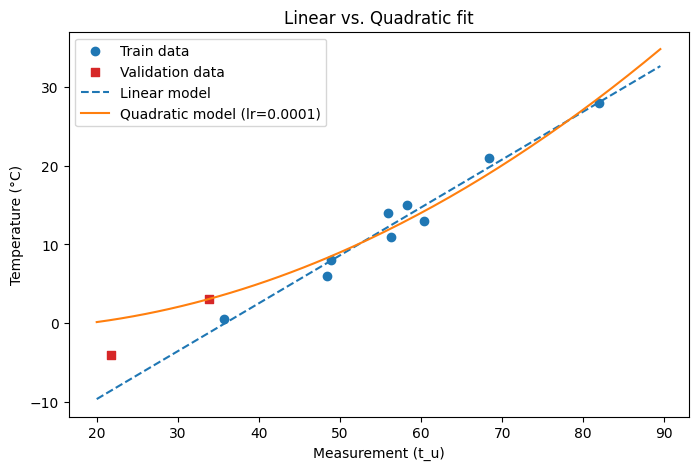

(545, 13)

=== Problem 2 (5 features), lr = 0.1 ===
Epoch 500, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 1000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 1500, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 2000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 2500, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 3000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 3500, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 4000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 4500, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 5000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591

=== Problem 2 (5 features), lr = 0.01 ===
Epoch 500, Train loss 0.4405, Val loss 0.5644, Val R2 0.5591
Epoch 1000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 1500, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 2000, Train loss 0.4405, Val loss 0.5643, Val R2 0.5591
Epoch 2500, Train loss 0.4405, Val loss

In [2]:
#Will Stevens
#Intro to ML HW 5

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


torch.manual_seed(0)  # same split for every run so results are comparable

t_c = torch.tensor([0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0])
t_u = torch.tensor([35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4])

n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples)

shuffled_indices = torch.randperm(n_samples)
train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

train_t_u, train_t_c = t_u[train_indices], t_c[train_indices]
val_t_u, val_t_c = t_u[val_indices], t_c[val_indices]

# normalize inputs (matters even more once we square them)
train_t_un = 0.1 * train_t_u
val_t_un = 0.1 * val_t_u

print("train:", train_indices.tolist(), "val:", val_indices.tolist())


import torch.optim as optim

def model_linear(t_u, w, b):
    return w * t_u + b

def model_quad(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    return ((t_p - t_c) ** 2).mean()

def training_loop(n_epochs, optimizer, model, params,
                  train_t_u, val_t_u, train_t_c, val_t_c, print_every=500):
    history = []  # (epoch, train_loss, val_loss) every print_every epochs
    for epoch in range(1, n_epochs + 1):
        train_t_p = model(train_t_u, *params)
        train_loss = loss_fn(train_t_p, train_t_c)

        with torch.no_grad():  # no backward on validation data
            val_t_p = model(val_t_u, *params)
            val_loss = loss_fn(val_t_p, val_t_c)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch % print_every == 0:
            history.append((epoch, train_loss.item(), val_loss.item()))
            print(f"Epoch {epoch}, Training loss {train_loss.item():.4f},"
                  f" Validation loss {val_loss.item():.4f}")
    return params, history

learning_rates = [1e-1, 1e-2, 1e-3, 1e-4]
results = {}

for lr in learning_rates:
    print(f"\n=== Quadratic model, lr = {lr} ===")
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)  # [w2, w1, b]
    optimizer = optim.SGD([params], lr=lr)
    params, history = training_loop(
        5000, optimizer, model_quad, params,
        train_t_un, val_t_un, train_t_c, val_t_c)
    results[lr] = {"params": params.detach().clone(), "history": history,
                   "train": history[-1][1], "val": history[-1][2]}

print("\nSummary (final epoch):")
for lr, r in results.items():
    print(f"lr={lr:<7} train={r['train']:.4f}  val={r['val']:.4f}  "
          f"params={r['params'].tolist()}")

# Pick best nonlinear run by validation loss (skip any that diverged to nan/inf)
valid = {lr: r for lr, r in results.items() if np.isfinite(r["val"])}
best_lr = min(valid, key=lambda k: valid[k]["val"])
best = results[best_lr]
print("Best quadratic lr:", best_lr, "| params [w2, w1, b]:", best["params"].tolist())

# Linear baseline (same split, lr=1e-2, 5000 epochs)
print("\n=== Linear baseline, lr = 0.01 ===")
params_lin = torch.tensor([1.0, 0.0], requires_grad=True)
opt_lin = optim.SGD([params_lin], lr=1e-2)
params_lin, hist_lin = training_loop(
    5000, opt_lin, model_linear, params_lin,
    train_t_un, val_t_un, train_t_c, val_t_c)
params_lin = params_lin.detach()

print(f"\nLinear    : train={hist_lin[-1][1]:.4f}  val={hist_lin[-1][2]:.4f}")
print(f"Quadratic : train={best['train']:.4f}  val={best['val']:.4f}")

# Plot over the input dataset
t_range = torch.arange(20.0, 90.0, 0.5)
t_range_n = 0.1 * t_range
with torch.no_grad():
    lin_curve = model_linear(t_range_n, *params_lin)
    quad_curve = model_quad(t_range_n, *best["params"])

plt.figure(figsize=(8, 5))
plt.scatter(train_t_u, train_t_c, c="tab:blue", label="Train data")
plt.scatter(val_t_u, val_t_c, c="tab:red", marker="s", label="Validation data")
plt.plot(t_range, lin_curve, "--", label="Linear model")
plt.plot(t_range, quad_curve, "-", label=f"Quadratic model (lr={best_lr})")
plt.xlabel("Measurement (t_u)")
plt.ylabel("Temperature (°C)")
plt.title("Linear vs. Quadratic fit")
plt.legend()
plt.show()


import torch.optim as optim

df = pd.read_csv("Housing.csv")
print(df.shape)

# 80/20 split, shared by Problems 2 and 3 so they are comparable
torch.manual_seed(0)
n = len(df)
n_val = int(0.2 * n)
perm = torch.randperm(n)
tr_idx, va_idx = perm[:-n_val], perm[-n_val:]

# yes/no -> 1/0, furnishingstatus -> one-hot (drop_first avoids a redundant column)
binary_cols = ["mainroad", "guestroom", "basement", "hotwaterheating",
               "airconditioning", "prefarea"]
df_enc = df.copy()
for c in binary_cols:
    df_enc[c] = (df_enc[c] == "yes").astype(int)
df_enc = pd.get_dummies(df_enc, columns=["furnishingstatus"], drop_first=True, dtype=int)

feats_p2 = ["area", "bedrooms", "bathrooms", "stories", "parking"]
feats_p3 = [c for c in df_enc.columns if c != "price"]

def loss_fn(t_p, t_c):
    return ((t_p - t_c) ** 2).mean()

def prepare(feature_cols):
    X = torch.tensor(df_enc[feature_cols].values.astype("float32"))
    y = torch.tensor(df_enc["price"].values.astype("float32"))
    # standardize with TRAINING statistics only
    x_mu, x_sd = X[tr_idx].mean(0), X[tr_idx].std(0)
    y_mu, y_sd = y[tr_idx].mean(), y[tr_idx].std()
    Xs, ys = (X - x_mu) / x_sd, (y - y_mu) / y_sd
    return dict(X_tr=Xs[tr_idx], y_tr=ys[tr_idx], X_va=Xs[va_idx], y_va=ys[va_idx],
                x_mu=x_mu, x_sd=x_sd, y_mu=y_mu, y_sd=y_sd, cols=feature_cols)

def train_linear(d, lr, n_epochs=5000, print_every=500):
    w = torch.zeros(d["X_tr"].shape[1], requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    optimizer = optim.SGD([w, b], lr=lr)
    history = []
    for epoch in range(1, n_epochs + 1):
        train_loss = loss_fn(d["X_tr"] @ w + b, d["y_tr"])
        with torch.no_grad():  # no backward on validation data
            val_p = d["X_va"] @ w + b
            val_loss = loss_fn(val_p, d["y_va"])
            val_r2 = 1 - val_loss / d["y_va"].var(unbiased=False)
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()
        if epoch % print_every == 0:
            history.append((epoch, train_loss.item(), val_loss.item(), val_r2.item()))
            print(f"Epoch {epoch}, Train loss {train_loss.item():.4f}, "
                  f"Val loss {val_loss.item():.4f}, Val R2 {val_r2.item():.4f}")
    return w.detach(), b.detach(), history

def run_problem(d, name):
    results = {}
    for lr in [1e-1, 1e-2, 1e-3, 1e-4]:
        print(f"\n=== {name}, lr = {lr} ===")
        w, b, hist = train_linear(d, lr)
        results[lr] = dict(w=w, b=b, hist=hist,
                           train=hist[-1][1], val=hist[-1][2], r2=hist[-1][3])
    print("\nSummary (final epoch):")
    for lr, r in results.items():
        print(f"lr={lr:<7} train={r['train']:.4f}  val={r['val']:.4f}  val R2={r['r2']:.4f}")
    valid = {lr: r for lr, r in results.items() if np.isfinite(r["val"])}
    best_lr = min(valid, key=lambda k: valid[k]["val"])
    return results, best_lr

def to_original_units(d, w, b):
    w_raw = w * d["y_sd"] / d["x_sd"]
    b_raw = d["y_mu"] + d["y_sd"] * (b - (w * d["x_mu"] / d["x_sd"]).sum())
    return w_raw, b_raw

def report(d, w, b, label):
    w_raw, b_raw = to_original_units(d, w, b)
    with torch.no_grad():
        val_p = d["X_va"] @ w + b
        rmse = ((val_p - d["y_va"]).pow(2).mean().sqrt() * d["y_sd"]).item()
        r2 = (1 - loss_fn(val_p, d["y_va"]) / d["y_va"].var(unbiased=False)).item()
    print(f"\n{label}: val RMSE = ${rmse:,.0f}, val R2 = {r2:.4f}")
    print(f"  bias = {b_raw.item():,.1f}")
    for c, v in zip(d["cols"], w_raw):
        print(f"  {c:<32}{v.item():>16,.2f}")

def exact_solution(d):  # closed-form least squares, as a convergence check
    Xb = torch.cat([d["X_tr"], torch.ones(len(d["X_tr"]), 1)], dim=1)
    sol = torch.linalg.lstsq(Xb, d["y_tr"].unsqueeze(1)).solution.squeeze(1)
    return sol[:-1], sol[-1:]

d2 = prepare(feats_p2)
res2, best_lr2 = run_problem(d2, "Problem 2 (5 features)")
print("Best lr:", best_lr2)
report(d2, res2[best_lr2]["w"], res2[best_lr2]["b"],
       f"Problem 2 gradient descent (lr={best_lr2})")
w_ex, b_ex = exact_solution(d2)
report(d2, w_ex, b_ex, "Problem 2 exact least squares (reference)")

d3 = prepare(feats_p3)
res3, best_lr3 = run_problem(d3, "Problem 3 (all features)")
print("Best lr:", best_lr3)
report(d3, res3[best_lr3]["w"], res3[best_lr3]["b"],
       f"Problem 3 gradient descent (lr={best_lr3})")
w_ex, b_ex = exact_solution(d3)
report(d3, w_ex, b_ex, "Problem 3 exact least squares (reference)")